In [20]:
!pip install -q pgmpy

/usr/local/lib/python3.13/dist-packages/pgmpy/estimators/__init__.py:4: FutureWarning: `pgmpy.estimators.StructureScore` is deprecated and will be removed in v1.3.0. Use `pgmpy.structure_score` instead.
  from .StructureScore import (


 Sample Size  Approx P(Lung=1|Xray=1,Cough=1)  Exact
         100                           0.9091 0.8592
         300                           0.9143 0.8592
         600                           0.8750 0.8592
        1200                           0.8819 0.8592
        2000                           0.8786 0.8592
        3000                           0.8585 0.8592


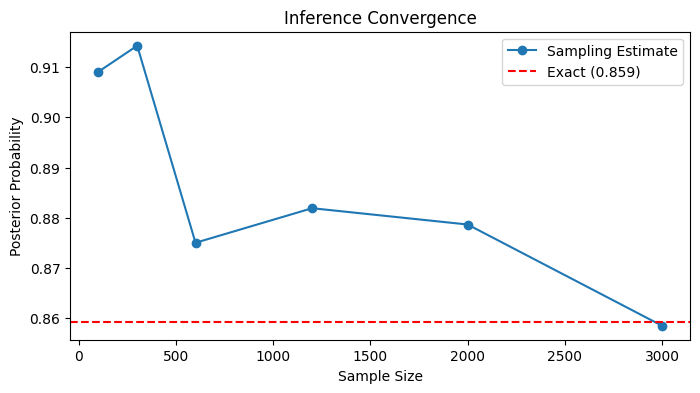

In [21]:
# !pip install -q pgmpy
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from pgmpy.models import DiscreteBayesianNetwork
from pgmpy.factors.discrete import TabularCPD
from pgmpy.inference import VariableElimination
from pgmpy.sampling import BayesianModelSampling

bn = DiscreteBayesianNetwork([
    ("Smoking", "LungDisease"), ("Pollution", "LungDisease"),
    ("LungDisease", "Cough"), ("LungDisease", "Xray"), ("LungDisease", "Fatigue")
])
bn.add_cpds(
    TabularCPD("Smoking", 2, [[0.7], [0.3]]),
    TabularCPD("Pollution", 2, [[0.8], [0.2]]),
    TabularCPD("LungDisease", 2, [[0.98, 0.85, 0.70, 0.20], [0.02, 0.15, 0.30, 0.80]],
               evidence=["Smoking", "Pollution"], evidence_card=[2, 2]),
    TabularCPD("Cough", 2, [[0.8, 0.2], [0.2, 0.8]], evidence=["LungDisease"], evidence_card=[2]),
    TabularCPD("Xray", 2, [[0.9, 0.15], [0.1, 0.85]], evidence=["LungDisease"], evidence_card=[2]),
    TabularCPD("Fatigue", 2, [[0.75, 0.3], [0.25, 0.7]], evidence=["LungDisease"], evidence_card=[2]),
)

exact_q = VariableElimination(bn).query(["LungDisease"], evidence={"Xray": 1, "Cough": 1})
exact_prob = float(exact_q.values[1])

sampler = BayesianModelSampling(bn)
samples = sampler.forward_sample(size=3000, show_progress=False)

sizes = [100, 300, 600, 1200, 2000, 3000]
est_probs = []
for n in sizes:
    sub = samples.iloc[:n]
    ev = sub[(sub["Xray"] == 1) & (sub["Cough"] == 1)]
    est_probs.append(float((ev["LungDisease"] == 1).mean()) if len(ev) > 0 else np.nan)

df_comp = pd.DataFrame({"Sample Size": sizes, "Approx P(Lung=1|Xray=1,Cough=1)": np.round(est_probs, 4), "Exact": round(exact_prob, 4)})
print(df_comp.to_string(index=False))

plt.figure(figsize=(8, 4))
plt.plot(sizes, est_probs, marker="o", label="Sampling Estimate")
plt.axhline(exact_prob, color="red", linestyle="--", label=f"Exact ({exact_prob:.3f})")
plt.xlabel("Sample Size"); plt.ylabel("Posterior Probability"); plt.title("Inference Convergence"); plt.legend(); plt.show()